# LAB 3 – Bài 1 (Trang 1): Phân lớp bộ dữ liệu Iris
Decision Tree, Naïve Bayes, KNN và Neural Network

In [1]:
HO_TEN = "Trang Kim Đạt"
MSSV = "6451071018"
print(f"{HO_TEN} – {MSSV}")

Trang Kim Đạt – 6451071018


In [2]:
print(f"{HO_TEN} – {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

Trang Kim Đạt – 6451071018


C:\Users\trang\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [3]:
print(f"{HO_TEN} – {MSSV}")
def danh_gia(ten_mo_hinh, y_true, y_pred, target_names=None):
    """In Accuracy, Precision/Recall/F1 (từng lớp + trung bình) và vẽ confusion matrix dạng heatmap."""
    print(f"===== {ten_mo_hinh} =====")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, target_names=target_names, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=target_names if target_names is not None else "auto",
                yticklabels=target_names if target_names is not None else "auto")
    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thực tế")
    plt.title(f"Confusion matrix - {ten_mo_hinh}")
    plt.show()

Trang Kim Đạt – 6451071018


## Câu a) Đọc bộ dữ liệu Iris từ sklearn

In [4]:
print(f"{HO_TEN} – {MSSV}")
iris = load_iris()

Trang Kim Đạt – 6451071018


## Câu b) Khảo sát bộ dữ liệu

In [5]:
print(f"{HO_TEN} – {MSSV}")
print("Tên các thuộc tính:", iris.feature_names)
print("Tên các lớp (thuộc tính phân lớp):", list(iris.target_names))
print("Số lượng mẫu, số lượng thuộc tính:", iris.data.shape)
print("Kích thước target:", iris.target.shape)
print("\n5 mẫu dữ liệu đầu tiên:")
print(iris.data[:5])
print("Nhãn tương ứng:", iris.target[:5])

Trang Kim Đạt – 6451071018
Tên các thuộc tính: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Tên các lớp (thuộc tính phân lớp): [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Số lượng mẫu, số lượng thuộc tính: (150, 4)
Kích thước target: (150,)

5 mẫu dữ liệu đầu tiên:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Nhãn tương ứng: [0 0 0 0 0]


In [6]:
print(f"{HO_TEN} – {MSSV}")
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target
df.describe()

Trang Kim Đạt – 6451071018


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## Câu c) Chuẩn hóa dữ liệu về đoạn [0, 1]
Chia mỗi giá trị của X cho giá trị lớn nhất của cột tương ứng.

In [7]:
print(f"{HO_TEN} – {MSSV}")
X = iris.data
Y = iris.target
X_max = X.max(axis=0)
X = X / X_max
print("Max từng cột sau chuẩn hóa:", X.max(axis=0))
print("Min từng cột sau chuẩn hóa:", X.min(axis=0).round(3))

Trang Kim Đạt – 6451071018
Max từng cột sau chuẩn hóa: [1. 1. 1. 1.]
Min từng cột sau chuẩn hóa: [0.544 0.455 0.145 0.04 ]


## Câu d) Chia train / test theo tỷ lệ 8:2

In [8]:
print(f"{HO_TEN} – {MSSV}")
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

Trang Kim Đạt – 6451071018
X_train: (120, 4) | X_test: (30, 4)
y_train: (120,) | y_test: (30,)


## Câu e) Decision Tree

Trang Kim Đạt – 6451071018


===== Decision Tree =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



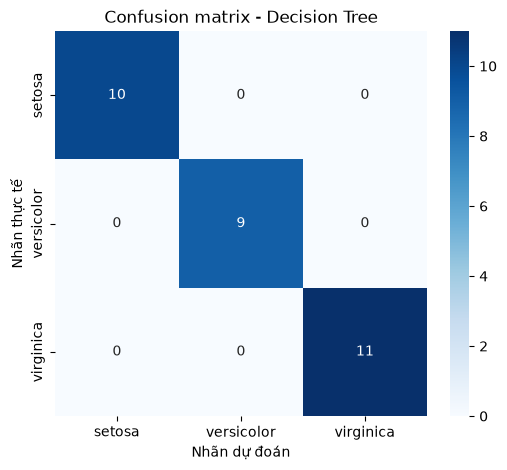

In [9]:
print(f"{HO_TEN} – {MSSV}")
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
danh_gia("Decision Tree", y_test, y_pred_dt, iris.target_names)

## Câu f) Naïve Bayes

Trang Kim Đạt – 6451071018
===== Naive Bayes =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



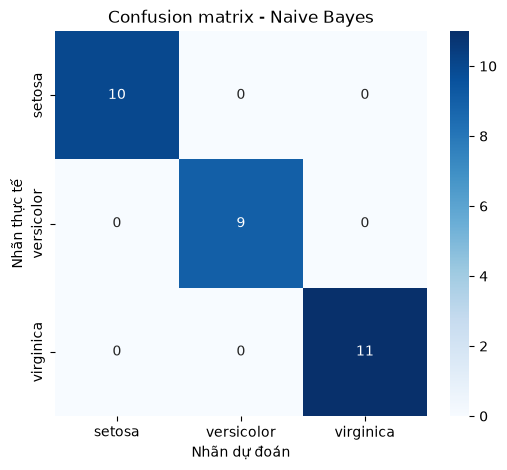

In [10]:
print(f"{HO_TEN} – {MSSV}")
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)
danh_gia("Naive Bayes", y_test, y_pred_nb, iris.target_names)

## Câu g) K Nearest Neighbors

Trang Kim Đạt – 6451071018
===== KNN (k=5) =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



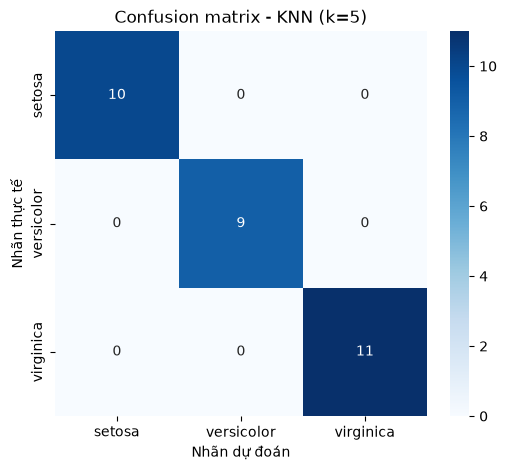

In [11]:
print(f"{HO_TEN} – {MSSV}")
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
danh_gia("KNN (k=5)", y_test, y_pred_knn, iris.target_names)

## Câu h) Neural Network
2 hidden layers (10 và 20 neuron, ReLU) + output layer (Softmax), adam, `sparse_categorical_crossentropy`, 100 epoch, batch_size = 1.

In [12]:
print(f"{HO_TEN} – {MSSV}")
so_lop = len(iris.target_names)
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(10, activation="relu"),
    Dense(20, activation="relu"),
    Dense(so_lop, activation="softmax"),
])
model.summary()

Trang Kim Đạt – 6451071018


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333 (1.30 KB)

 Trainable params: 333 (1.30 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
print(f"{HO_TEN} – {MSSV}")
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=100, batch_size=1, verbose=1)

Trang Kim Đạt – 6451071018


Epoch 1/100


  1/120 ━━━━━━━━━━━━━━━━━━━━ 8:54 4s/step - accuracy: 1.0000 - loss: 0.8995

 11/120 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1818 - loss: 1.0619 

 24/120 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2500 - loss: 1.1088

 36/120 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1667 - loss: 1.1150

... (997 outputs left out)

 71/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9859 - loss: 0.0395

 89/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9775 - loss: 0.0626

107/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9720 - loss: 0.0688

120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9750 - loss: 0.0741


Trang Kim Đạt – 6451071018


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step


===== Neural Network =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



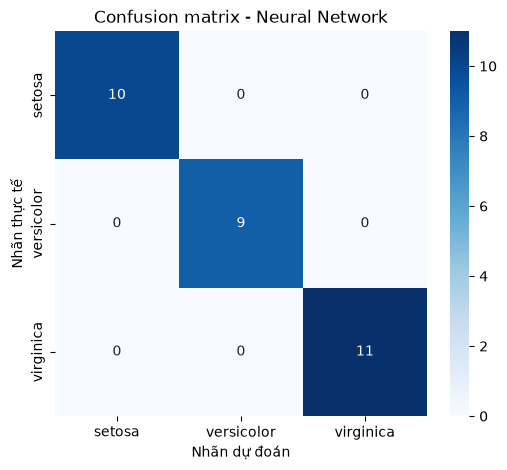

In [14]:
print(f"{HO_TEN} – {MSSV}")
y_prob_nn = model.predict(X_test)
y_pred_nn = np.argmax(y_prob_nn, axis=1)
danh_gia("Neural Network", y_test, y_pred_nn, iris.target_names)

## Câu i) Dự đoán 3 mẫu dữ liệu mới bằng các mô hình đã huấn luyện
Các mẫu mới phải được chuẩn hóa bằng **cùng** giá trị max của tập dữ liệu gốc.

In [15]:
print(f"{HO_TEN} – {MSSV}")
mau_moi = np.array([[6.2, 2.9, 4.3, 1.3],
                    [5.1, 3.5, 1.4, 0.2],
                    [7.3, 2.8, 6.4, 2.1]])
mau_moi_chuan_hoa = mau_moi / X_max

du_doan = {
    "Decision Tree": dt.predict(mau_moi_chuan_hoa),
    "Naive Bayes": nb.predict(mau_moi_chuan_hoa),
    "KNN": knn.predict(mau_moi_chuan_hoa),
    "Neural Network": np.argmax(model.predict(mau_moi_chuan_hoa), axis=1),
}
kq = pd.DataFrame({ten: iris.target_names[v] for ten, v in du_doan.items()})
kq.insert(0, "Mẫu", [str(m) for m in mau_moi.tolist()])
kq

Trang Kim Đạt – 6451071018
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step


,Mẫu,Decision Tree,Naive Bayes,KNN,Neural Network
0,"[6.2, 2.9, 4.3, 1.3]",versicolor,versicolor,versicolor,versicolor
1,"[5.1, 3.5, 1.4, 0.2]",setosa,setosa,setosa,setosa
2,"[7.3, 2.8, 6.4, 2.1]",virginica,virginica,virginica,virginica


## Câu j) Nhận xét, đánh giá hiệu suất các mô hình

In [16]:
print(f"{HO_TEN} – {MSSV}")
ket_qua = {"Decision Tree": y_pred_dt, "Naive Bayes": y_pred_nb, "KNN": y_pred_knn, "Neural Network": y_pred_nn}
bang = pd.DataFrame({
    "Accuracy": {k: accuracy_score(y_test, v) for k, v in ket_qua.items()},
    "F1-macro": {k: f1_score(y_test, v, average="macro") for k, v in ket_qua.items()},
    "Số mẫu dự đoán sai": {k: int((v != y_test).sum()) for k, v in ket_qua.items()},
}).round(4)
display(bang)
tot_nhat = bang["Accuracy"].max()
print("Mô hình có Accuracy cao nhất:", ", ".join(bang.index[bang["Accuracy"] == tot_nhat]), f"({tot_nhat:.4f})")

Trang Kim Đạt – 6451071018


,Accuracy,F1-macro,Số mẫu dự đoán sai
Decision Tree,1.0,1.0,0
Naive Bayes,1.0,1.0,0
KNN,1.0,1.0,0
Neural Network,1.0,1.0,0


Mô hình có Accuracy cao nhất: Decision Tree, Naive Bayes, KNN, Neural Network (1.0000)


**Nhận xét chung**

- Iris là bộ dữ liệu nhỏ (150 mẫu), tập test chỉ có 30 mẫu nên mỗi mẫu dự đoán sai làm Accuracy giảm ≈ 3,33%. Do đó chênh lệch giữa các mô hình rất nhỏ và phụ thuộc vào cách chia train/test.
- Với cách chia train/test (random_state = 42) trong bài này, cả 4 mô hình đều đạt Accuracy 100% trên tập test (xem bảng); với cách chia khác kết quả có thể lệch 1–2 mẫu.
- Lớp *setosa* tách biệt tuyến tính với hai lớp còn lại nên mọi mô hình đều phân lớp đúng; lỗi (nếu có) chỉ xảy ra giữa *versicolor* và *virginica* (hai lớp chồng lấn nhau).
- Decision Tree dễ diễn giải nhưng dễ overfit; Naïve Bayes (Gaussian) đơn giản, nhanh, giả định các thuộc tính độc lập; KNN không cần huấn luyện nhưng phụ thuộc vào tham số k và việc chuẩn hóa dữ liệu; Neural Network cần nhiều thời gian huấn luyện hơn (100 epoch, batch_size = 1) nhưng linh hoạt, cho kết quả cạnh tranh trên dữ liệu đã chuẩn hóa.
- Với dữ liệu nhỏ và đơn giản như Iris, các mô hình đơn giản (KNN, Naïve Bayes) cho hiệu quả tương đương Neural Network với chi phí tính toán thấp hơn nhiều. Bảng số liệu ở trên là căn cứ để so sánh cụ thể.